In [8]:
import numpy as np
import cv2
import glob
import matplotlib.pyplot as plt
import open3d as o3d
import os
Q = np.array([[ 1.00000000e+00,0.00000000e+00,0.00000000e+00, -6.34176018e+02],
 [ 0.00000000e+00,  1.00000000e+00,  0.00000000e+00, -3.98794449e+02],
 [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  6.69875449e+02],
 [ 0.00000000e+00,  0.00000000e+00 , 8.25978335e-03 ,-0.00000000e+00]])

In [9]:
def calc_disparity(left_path, right_path):
    left_rect = cv2.imread(left_path, cv2.IMREAD_GRAYSCALE)
    right_rect = cv2.imread(right_path, cv2.IMREAD_GRAYSCALE)
    
    min_disparity = 2
    max_disparity = 60
    baseline_mm= 1/8.25978335e-03
    
    stereo = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=6*16,      # must be a multiple of 16
        blockSize=5,
        P1=8 * 5 * 5,
        P2=32 * 5 * 5,
        uniquenessRatio=10,
        speckleWindowSize=100,
        speckleRange=2,
        disp12MaxDiff=1,
        preFilterCap=31,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
    )
    
    disp = stereo.compute(left_rect, right_rect).astype(np.float32) / 16.0
    return disp


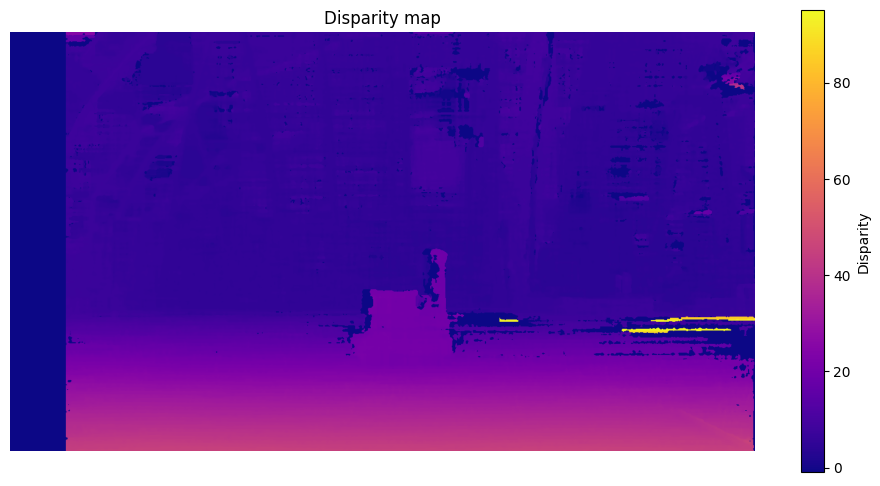

In [4]:
plt.figure(figsize=(12, 6))
plt.imshow(disp, cmap="plasma")
plt.colorbar(label="Disparity")
plt.title("Disparity map")
plt.axis("off")
plt.show()

In [10]:
def calc_pointcloud(disp, left_path):
    # Use interpolated disparity directly
    disparity_3D = disp.astype(np.float32)
    
    # Reconstruct 3D points
    points_3D = cv2.reprojectImageTo3D(disparity_3D,Q)
    
    left_color = cv2.imread(left_path,cv2.IMREAD_COLOR)
    left_color = cv2.cvtColor(left_color, cv2.COLOR_BGR2RGB)
    # Normalize colors between 0 and 1 for Open3D
    colors = left_color.astype(np.float32) / 255.0
    valid_mask = ((disp > 1) & np.isfinite(points_3D).all(axis=2))
    cloud = points_3D[valid_mask]
    cloud_colors = colors[valid_mask]
    
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(cloud)
    pcd.colors = o3d.utility.Vector3dVector(cloud_colors)
    #o3d.visualization.draw_geometries([pcd])
    return pcd 

In [ ]:
for seq in ["0_calib","1_no_obstacle", "2_obstacle", "3_curved_bend", "4_circle"]:
    os.makedirs(f"Disparity/{seq}", exist_ok=True)
    os.makedirs(f"Pointcloud/{seq}", exist_ok=True)

    seq_left = sorted(glob.glob(f"{seq}/left/*.png"))
    seq_right = sorted(glob.glob(f"{seq}/right/*.png"))

    for left_path, right_path in zip(seq_left, seq_right):
        disp = calc_disparity(left_path, right_path)
        pcd = calc_pointcloud(disp, left_path)

        cv2.imwrite(f"Disparity/{seq}/" + os.path.basename(left_path), disp)
        o3d.io.write_point_cloud(f"Pointcloud/{seq}/" + os.path.basename(left_path) + ".ply", pcd)

    print("Saved:", seq, len(seq_left), "pairs")

Saved: 0_calib 37 pairs
Saved: 1_no_obstacle 256 pairs


Trying to remove disparity values that seem too far

In [3]:
# Identify invalid disparity values
invalid_mask = (disp < min_disparity) | (disp > max_disparity)
# Keep original disparity values
disp_filtered = disp.copy()
# Set invalid pixels to zero
disp_filtered[invalid_mask] = 0
# Define neighborhood kernel (5x5)
kernel = np.ones((11, 11), np.float32)
kernel[5, 5] = 0  # Exclude center pixel
max_iterations = 20
for iteration in range(max_iterations):
    # Identify pixels that are still invalid
    invalid_mask = (disp_filtered == 0)

    if not np.any(invalid_mask):
        break
    # Sum of valid neighboring disparities
    local_sum = cv2.filter2D(disp_filtered,-1,kernel,borderType=cv2.BORDER_CONSTANT)
    # Count valid neighbors
    local_count = cv2.filter2D((disp_filtered > 0).astype(np.float32),-1,kernel,borderType=cv2.BORDER_CONSTANT)
    # Pixels that can be interpolated
    fillable = invalid_mask & (local_count > 0)
    if not np.any(fillable):
        break

    # Calculate local mean
    local_mean = local_sum / np.maximum(local_count, 1)
    # Update only pixels that can be filled
    disp_filtered[fillable] = local_mean[fillable]
    


In [ ]:
# Remove invalid points
valid_mask = ((disp_filtered > 0) & np.isfinite(points_3D).all(axis=2))
cloud = points_3D[valid_mask]
cloud_colors = colors[valid_mask]
# Keep only plausible depth values (in mm)
z = cloud[:, 2]
depth_mask = (z > 10) & (z < 8000)

cloud = cloud[depth_mask]
cloud_colors = cloud_colors[depth_mask]

Trying the left and right consistency checking

In [34]:

# Create right matcher
right_matcher = cv2.ximgproc.createRightMatcher(stereo)

# Calculate disparities
disp_left = stereo.compute(
    left_rect, right_rect
).astype(np.float32) / 16.0

disp_right = right_matcher.compute(
    right_rect, left_rect
).astype(np.float32) / 16.0

h, w = disp_left.shape

# Corresponding pixel coordinates in right image
x = np.tile(np.arange(w), (h, 1))
x_right = np.round(x - disp_left).astype(np.int32)

# Check image boundaries
inside = (x_right >= 0) & (x_right < w)

# Clip coordinates for safe indexing
x_right_safe = np.clip(x_right, 0, w - 1)

# Get corresponding right disparities
rows = np.arange(h)[:, None]
right_at_correspondence = disp_right[rows, x_right_safe]

# Left-right consistency
consistency_error = np.abs(
    disp_left + right_at_correspondence
)

# Keep reliable disparities
valid_mask = (
    (disp_left > 5) &
    inside &
    (consistency_error < 1.5)
)

# Preserve original disparity values
disp_filtered = disp_left.copy()
disp_filtered[~valid_mask] = 0


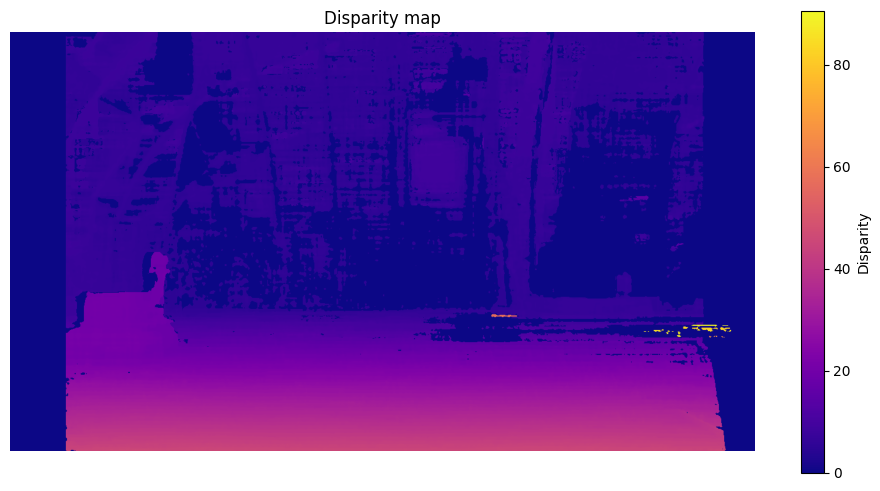

In [35]:
plt.figure(figsize=(12, 6))
plt.imshow(disp_filtered, cmap="plasma")
plt.colorbar(label="Disparity")
plt.title("Disparity map")
plt.axis("off")
plt.show()

Trying to get a background disparity map as a background

In [62]:
import cv2
import numpy as np
import glob
import os

left_files = sorted(glob.glob("rectified/1_no_obstacle/left/*.png"))
right_files = sorted(glob.glob("rectified/1_no_obstacle/right/*.png"))

# Use only the first 65 pairs: frames 0 to 64 that are only background
left_files = left_files[:65]
right_files = right_files[:65]
background_disparities = []
min_disparity = 2
max_disparity = 60
baseline_mm= 1/8.25978335e-03

stereo = cv2.StereoSGBM_create(
    minDisparity=0,
    numDisparities=6*16,      # must be a multiple of 16
    blockSize=5,
    P1=8 * 5 * 5,
    P2=32 * 5 * 5,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=2,
    disp12MaxDiff=1,
    preFilterCap=31,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)

for left_path, right_path in zip(left_files, right_files):

    left = cv2.imread(left_path, cv2.IMREAD_GRAYSCALE)
    right = cv2.imread(right_path, cv2.IMREAD_GRAYSCALE)

    disp = stereo.compute(left, right).astype(np.float32) / 16.0

    # Reject invalid and very small disparities
    disp[disp <= 1] = np.nan

    background_disparities.append(disp)

background_stack = np.stack(background_disparities, axis=0)

# Count valid disparity measurements per pixel
valid_count = np.sum(np.isfinite(background_stack), axis=0)

# Initialize background disparity with NaN
background_disparity = np.full(
    background_stack.shape[1:],
    np.nan,
    dtype=np.float32
)

# Only calculate median where at least one valid value exists
valid_pixels = valid_count > 0

background_disparity[valid_pixels] = np.nanmedian(
    background_stack[:, valid_pixels],
    axis=0
)

# Require at least 33 valid measurements out of 65
background_disparity[valid_count < 33] = np.nan

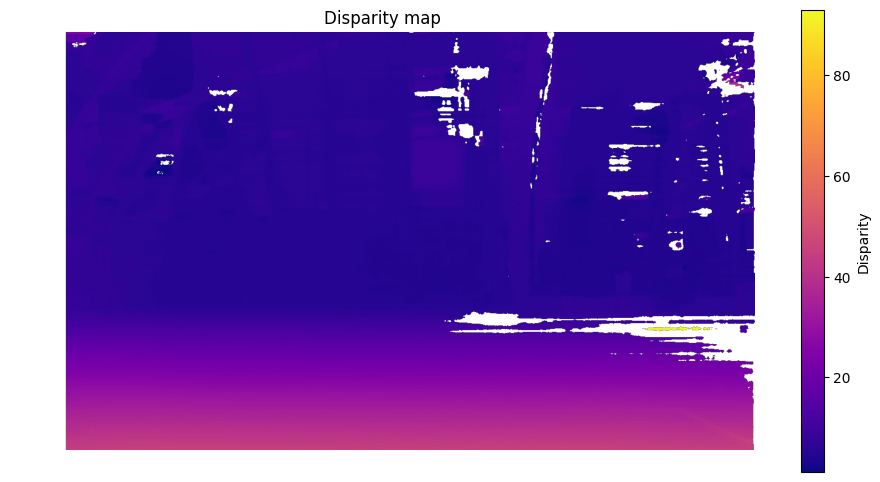

In [3]:
plt.figure(figsize=(12, 6))
plt.imshow(background_disparity, cmap="plasma")
plt.colorbar(label="Disparity")
plt.title("Disparity map")
plt.axis("off")
plt.show()

In [4]:
total_pixels = background_disparity.size
valid_pixels = np.sum(np.isfinite(background_disparity))

print(f"Valid background pixels: {100 * valid_pixels / total_pixels:.2f}%")
print(f"Invalid background pixels: {100 * (1 - valid_pixels / total_pixels):.2f}%")

Valid background pixels: 89.44%
Invalid background pixels: 10.56%


In [ ]:
# Use interpolated disparity directly
disparity_3D = background_disparity.astype(np.float32)

#Get the colors to reconstruct the scene
left_color = cv2.imread("rectified/1_no_obstacle/left/000064.png",cv2.IMREAD_COLOR)
left_color = cv2.cvtColor(left_color, cv2.COLOR_BGR2RGB)
# Normalize colors between 0 and 1 for Open3D
colors = left_color.astype(np.float32) / 255.0

# Reconstruct 3D points
points_3D = cv2.reprojectImageTo3D(disparity_3D,Q)
# Remove invalid points
valid_mask = ((background_disparity > 0) & np.isfinite(points_3D).all(axis=2))
cloud = points_3D[valid_mask]
cloud_colors = colors[valid_mask]
# Keep only plausible depth values (in mm)
z = cloud[:, 2]
depth_mask = (z > 10) & (z < 20000)

cloud = cloud[depth_mask]
cloud_colors = cloud_colors[depth_mask]


background_pcd = o3d.geometry.PointCloud()
background_pcd.points = o3d.utility.Vector3dVector(cloud)
background_pcd.colors = o3d.utility.Vector3dVector(cloud_colors)
o3d.visualization.draw_geometries([background_pcd])

We have a better representation of the background but with still streched elements, we could use temporal filter to improve depth data from previous frames. 
Spatial filter is also a solution to fill invalid piwels with valid neighbors.
Moreover, there is the bright spots that are invalid spots that can be reduces using Brightness filter. 
The order of the post processing filters is important, Temporal>Speckle>Spatial>Median>Decimation
https://docs.luxonis.com/hardware/platform/depth/configuring-stereo-depth/#Configuring%20Stereo%20Depth-Improving%20depth%20accuracy 

In [ ]:
#Reconstruct 3D scene for each pair and save the 3D pointcloud



In [15]:
for seq in ["0_calib"]:
    os.makedirs(f"3D/{seq}", exist_ok=True)

    seq_left = sorted(glob.glob(f"{seq}/left/*.png"))
    seq_right = sorted(glob.glob(f"{seq}/right/*.png"))

    for left_path, right_path in zip(seq_left, seq_right):
        current_pcd, current_disp, current_3d, valid_current = pcd(left_path, right_path)
        diff = current_disp - background_disparity

        robot_mask = (np.isfinite(background_disparity) & np.isfinite(current_disp) & (diff > 2.0))
        robot_points = current_3d[robot_mask]

        robot_pcd = o3d.geometry.PointCloud()
        robot_pcd.points = o3d.utility.Vector3dVector(robot_points)
        if len(robot_points) >=30:
            labels = np.array(robot_pcd.cluster_dbscan(eps=50,min_points=30,print_progress=True))
    
            #Keep valid points 
            valid_labels = labels[labels >= 0]
            if len(valid_labels) > 0:
                # Find the largest cluster
                unique_labels, counts = np.unique(valid_labels,return_counts=True)
                robot_label = unique_labels[np.argmax(counts)]
    
                # Extract largest cluster
                cluster_points = np.asarray(robot_pcd.points)[labels == robot_label]
    
                # Calculate 3D position
                robot_position = np.mean(cluster_points, axis=0)
    
                print("Robot 3D position (mm):", robot_position)
    
                # Create point cloud containing only the selected cluster
                detected_robot_pcd = o3d.geometry.PointCloud()
                detected_robot_pcd.points = o3d.utility.Vector3dVector(cluster_points)
                o3d.visualization.draw_geometries([detected_robot_pcd])
                cv2.waitKey(800)
    
                # Save detected robot point cloud
                #o3d.io.write_point_cloud(f"3D/{seq}/robot/frame_{frame_idx:04d}.ply",detected_robot_pcd)
            else:
                print("No clusters detected")
                robot_position = None
    
        else:
            print("Not enough candidate points")
            robot_position = None

        # 7. Save complete scene point cloud
        #o3d.io.write_point_cloud(f"3D/{seq}/scene/frame_{frame_idx:04d}.ply",current_pcd)

Robot 3D position (mm): [ 546.66931595 -802.23482596 2689.93412063]


KeyboardInterrupt: 

Substract the background to the new frame to only have the robot 

In [26]:
#curren_pcd: the pointcloud
#disp: the disparity map
#current_3d: the 3D point array corresponding to the image pixels order
#valid_current: the mask identifying the valid 3D points
def pcd(left_path, right_path):
    min_disparity = 2
    max_disparity = 60
    baseline_mm= 1/8.25978335e-03
    
    stereo = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=6*16,      # must be a multiple of 16
        blockSize=5,
        P1=8 * 5 * 5,
        P2=32 * 5 * 5,
        uniquenessRatio=10,
        speckleWindowSize=100,
        speckleRange=2,
        disp12MaxDiff=1,
        preFilterCap=31,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
    )
    
    left = cv2.imread(left_path, cv2.IMREAD_GRAYSCALE)
    right = cv2.imread(right_path, cv2.IMREAD_GRAYSCALE)
    
    left_color = cv2.imread(left_path,cv2.IMREAD_COLOR)
    left_color = cv2.cvtColor(left_color, cv2.COLOR_BGR2RGB)
    # Normalize colors between 0 and 1 for Open3D
    colors = left_color.astype(np.float32) / 255.0

    disp = stereo.compute(left, right).astype(np.float32) / 16.0
    
    # Reject invalid and very small disparities
    disp[disp <= 1] = np.nan
    
    #Construct the 3D coordinates
    current_3d = cv2.reprojectImageTo3D(disp.astype(np.float32),Q)
    
    valid_current = (np.isfinite(disp) & (disp > 1) & np.isfinite(current_3d).all(axis=2))
    
    # Restrict depth to plausible values (mm)
    valid_current &= ((current_3d[:, :, 2] > 10) & (current_3d[:, :, 2] < 20000))

    # Extract valid 3D points
    current_points = current_3d[valid_current]
    cloud_colors = colors[valid_current]
    
    current_pcd = o3d.geometry.PointCloud()
    current_pcd.points = o3d.utility.Vector3dVector(current_points)
    current_pcd.colors = o3d.utility.Vector3dVector(cloud_colors)
    #o3d.visualization.draw_geometries([current_pcd])
    return current_pcd, disp, current_3d, valid_current, colors


In [27]:
current_pcd, current_disp, current_3d, valid_current, colors = pcd("rectified/1_no_obstacle/left/000100.png", "rectified/1_no_obstacle/right/000100.png")
diff = current_disp - background_disparity

robot_mask = (np.isfinite(background_disparity) & np.isfinite(current_disp) & (diff > 2.0))
robot_points = current_3d[robot_mask]
robot_colors = colors[robot_mask]

robot_pcd = o3d.geometry.PointCloud()
robot_pcd.points = o3d.utility.Vector3dVector(robot_points)
robot_pcd.colors = o3d.utility.Vector3dVector(robot_colors)
if len(robot_points) >=30:
    labels = np.array(robot_pcd.cluster_dbscan(eps=50,min_points=30,print_progress=True))

    #Keep valid points 
    valid_labels = labels[labels >= 0]
    if len(valid_labels) > 0:
        # Find the largest cluster
        unique_labels, counts = np.unique(valid_labels,return_counts=True)
        robot_label = unique_labels[np.argmax(counts)]

        # Extract largest cluster
        cluster_mask = labels == robot_label

        cluster_points = robot_points[cluster_mask]
        cluster_colors = robot_colors[cluster_mask]

        # Calculate 3D position
        robot_position = np.mean(cluster_points, axis=0)

        print("Robot 3D position (mm):", robot_position)

        # Create point cloud containing only the selected cluster
        detected_robot_pcd = o3d.geometry.PointCloud()
        detected_robot_pcd.points = o3d.utility.Vector3dVector(cluster_points)
        detected_robot_pcd.colors = o3d.utility.Vector3dVector(cluster_colors)
        o3d.visualization.draw_geometries([detected_robot_pcd])

Robot 3D position (mm): [-2679.5535   577.5458  4116.321 ]
